# Traffic Crash Models

Two studies, two datasets:

- `features.xls`
- `traffic_case_study.xlsx`

### Note: Claude Opus 5.5 was used as an assistant  

## Load the raw data

In [1]:
import pandas as pd

In [2]:
features = pd.read_excel("features.xls")
features.shape

(1030, 80)

In [3]:
features.head()

,AUTOMOBILE_COUNT,BUS_COUNT,COLLISION_TYPE,COUNTY,CRASH_MONTH,DAY_OF_WEEK,DRIVER_COUNT_16YR,DRIVER_COUNT_17YR,DRIVER_COUNT_18YR,DRIVER_COUNT_19YR,...,SPEEDING,STATE_ROAD,STOP_CONTROLLED_INT,SUDDEN_DEER,VULNERABLE_ROAD_USER,WET_ROAD,WORK_ZONE,YOUNG_DRIVER,LANE_COUNT,SPEED_LIMIT
0,1.0,0.0,2.0,2.0,5.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,25.0
1,1.0,0.0,2.0,2.0,5.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0,35.0
2,0.0,0.0,7.0,31.0,6.0,5.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,NaN,NaN,0.0,1.0,2.0,25.0
3,0.0,0.0,7.0,23.0,5.0,5.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,NaN,0.0,0.0,0.0,2.0,35.0
4,3.0,0.0,2.0,2.0,6.0,4.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,NaN,0.0,NaN,2.0,35.0


In [4]:
case_study = pd.read_excel("traffic_case_study.xlsx")
case_study.shape

(600, 26)

In [5]:
case_study.head()

,AUTOMOBILE_COUNT,SPEED_LIMIT,URBAN_RURAL,URBAN,YOUNG_DRIVER,COLLISION_TYPE,LANE_COUNT,BICYCLE_COUNT,BUS_COUNT,ILLUMINATION,...,DRUGGED_DRIVER,FATAL_OR_SUSP_SERIOUS_INJ,FATIGUE_ASLEEP,HIT_FIXED_OBJECT,LANE_DEPARTURE,MATURE_DRIVER,OVERTURNED,SCHOOL_ZONE,SPEEDING_RELATED,WET_ROAD
0,1,25.0,4,1.0,0.0,2,2.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,35.0,4,1.0,0.0,2,4.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,25.0,1,0.0,1.0,7,2.0,0,0.0,1,...,0,0,0,1,1,0,0,0,0,0
3,0,35.0,4,1.0,0.0,7,2.0,0,0.0,1,...,1,0,0,1,1,0,0,0,1,0
4,3,35.0,4,1.0,0.0,2,2.0,0,0.0,1,...,0,0,0,0,1,1,0,0,0,0


## Features data: missing values

In [6]:
nulls = features.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(len(nulls), "of", features.shape[1], "fields have null values\n")
print(nulls.to_string())

80 of 80 fields have null values

STOP_CONTROLLED_INT          264
DRIVER_50_64YR               264
DRIVER_20YR                  264
ILLUMINATION                 264
DAY_OF_WEEK                  263
CELL_PHONE                   240
SECONDARY_CRASH              237
CRASH_MONTH                  237
TIME_OF_DAY                  230
YOUNG_DRIVER                 230
SIGNALIZED_INT               228
VULNERABLE_ROAD_USER         225
BICYCLE                      223
WET_ROAD                     214
MOTORCYCLE                   213
MULTIPLE_VEHICLE             204
HOUR_OF_DAY                   30
HEAVY_TRUCK_COUNT             30
DRIVER_COUNT_75PLUS           30
DRIVER_COUNT_65_74YR          30
DRIVER_COUNT_50_64YR          30
DRIVER_COUNT_20YR             30
DRIVER_COUNT_19YR             30
DRIVER_COUNT_18YR             30
DRIVER_COUNT_17YR             30
DRIVER_COUNT_16YR             30
COLLISION_TYPE                30
COUNTY                        30
BUS_COUNT                     30
AUTOMOBIL

## Data Cleaning 

Got rid of rows 1000–1029 as theses were completly useless 

In [7]:
features = features.dropna(subset=["FATAL_OR_SUSP_SERIOUS_INJ"]).reset_index(drop=True)
features.shape

(1000, 80)

## Rural crashes only

The study focuses on rural roads, so only crashes with `RURAL` = 1 are kept.

In [8]:
features = features[features["RURAL"] == 1].reset_index(drop=True)
print(f"{len(features)} rural crashes, {int(features['FATAL_OR_SUSP_SERIOUS_INJ'].sum())} fatal / serious")

222 rural crashes, 13 fatal / serious


In [9]:
nulls = features.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(len(nulls), "of", features.shape[1], "fields have null values\n")
print(nulls.to_string())

16 of 80 fields have null values

SIGNALIZED_INT          53
MOTORCYCLE              53
YOUNG_DRIVER            51
TIME_OF_DAY             50
WET_ROAD                46
DAY_OF_WEEK             45
SECONDARY_CRASH         45
MULTIPLE_VEHICLE        45
CELL_PHONE              43
VULNERABLE_ROAD_USER    42
CRASH_MONTH             40
BICYCLE                 39
DRIVER_20YR             27
ILLUMINATION            27
DRIVER_50_64YR          27
STOP_CONTROLLED_INT     27


## Handling the missing values

| Field | Method |
|---|---|
| `CRASH_MONTH` | Dropped |
| `DAY_OF_WEEK` | Dropped |
| `TIME_OF_DAY` | Dropped (`HOUR_OF_DAY` has the same hour) |
| `ILLUMINATION` | Dropped (`ILLUMINATION_DARK` has dark / not dark) |
| `WET_ROAD` | Filled from `ROAD_CONDITION`: 08 (water) or 09 (wet) = 1 |
| `YOUNG_DRIVER` | Filled from driver counts: any driver aged 16–20 = 1 |
| `DRIVER_20YR` | Filled from `DRIVER_COUNT_20YR` > 0 |
| `DRIVER_50_64YR` | Filled from `DRIVER_COUNT_50_64YR` > 0 |
| `MULTIPLE_VEHICLE` | Filled from `VEHICLE_COUNT` ≥ 2 |
| `CELL_PHONE` | Not distracted = 0; remaining gaps: mean of distracted crashes |
| `SIGNALIZED_INT` | Not at an intersection = 0; remaining gaps: mean of intersection crashes |
| `STOP_CONTROLLED_INT` | Not at an intersection = 0; remaining gaps: mean of intersection crashes, plus a `STOP_CONTROLLED_INT_MISSING` flag |
| `VULNERABLE_ROAD_USER` | Pedestrian or bicycle involved = 1, neither = 0; remaining gaps: mean |
| `BICYCLE` | No vulnerable road user = 0; vulnerable road user but no pedestrian = 1; remaining gaps: mean |
| `MOTORCYCLE` | Mean, plus a `MOTORCYCLE_MISSING` flag |
| `SECONDARY_CRASH` | Mean |

In [10]:
df = features.copy()

# Dropped fields
df = df.drop(columns=["CRASH_MONTH", "DAY_OF_WEEK", "TIME_OF_DAY", "ILLUMINATION"])

# Filled from other columns
young_counts = ["DRIVER_COUNT_16YR", "DRIVER_COUNT_17YR", "DRIVER_COUNT_18YR", "DRIVER_COUNT_19YR", "DRIVER_COUNT_20YR"]
df["WET_ROAD"] = df["WET_ROAD"].fillna(df["ROAD_CONDITION"].isin([8, 9]).astype(float))
df["YOUNG_DRIVER"] = df["YOUNG_DRIVER"].fillna((df[young_counts].sum(axis=1) > 0).astype(float))
df["DRIVER_20YR"] = df["DRIVER_20YR"].fillna((df["DRIVER_COUNT_20YR"] > 0).astype(float))
df["DRIVER_50_64YR"] = df["DRIVER_50_64YR"].fillna((df["DRIVER_COUNT_50_64YR"] > 0).astype(float))
df["MULTIPLE_VEHICLE"] = df["MULTIPLE_VEHICLE"].fillna((df["VEHICLE_COUNT"] >= 2).astype(float))

In [11]:
# Partly filled from other columns, remaining gaps filled with a mean

# CELL_PHONE
cell_mean = df.loc[df["DISTRACTED"] == 1, "CELL_PHONE"].mean()
df.loc[df["CELL_PHONE"].isna() & (df["DISTRACTED"] == 0), "CELL_PHONE"] = 0
df["CELL_PHONE"] = df["CELL_PHONE"].fillna(cell_mean)

# SIGNALIZED_INT
signal_mean = df.loc[df["INTERSECTION"] == 1, "SIGNALIZED_INT"].mean()
df.loc[df["SIGNALIZED_INT"].isna() & (df["INTERSECTION"] == 0), "SIGNALIZED_INT"] = 0
df["SIGNALIZED_INT"] = df["SIGNALIZED_INT"].fillna(signal_mean)

# STOP_CONTROLLED_INT (with a flag for the mean-filled rows)
stop_mean = df.loc[df["INTERSECTION"] == 1, "STOP_CONTROLLED_INT"].mean()
df.loc[df["STOP_CONTROLLED_INT"].isna() & (df["INTERSECTION"] == 0), "STOP_CONTROLLED_INT"] = 0
df["STOP_CONTROLLED_INT_MISSING"] = df["STOP_CONTROLLED_INT"].isna().astype(int)
df["STOP_CONTROLLED_INT"] = df["STOP_CONTROLLED_INT"].fillna(stop_mean)

# VULNERABLE_ROAD_USER and BICYCLE (each helps fill the other, using the original values)
vru, bike = df["VULNERABLE_ROAD_USER"].copy(), df["BICYCLE"].copy()
vru_mean, bike_mean = vru.mean(), bike.mean()

df.loc[vru.isna() & (df["PED_COUNT"] > 0), "VULNERABLE_ROAD_USER"] = 1
df.loc[vru.isna() & (df["PED_COUNT"] == 0) & bike.notna(), "VULNERABLE_ROAD_USER"] = bike
df.loc[bike.isna() & (vru == 0), "BICYCLE"] = 0
df.loc[bike.isna() & (vru == 1) & (df["PED_COUNT"] == 0), "BICYCLE"] = 1

df["VULNERABLE_ROAD_USER"] = df["VULNERABLE_ROAD_USER"].fillna(vru_mean)
df["BICYCLE"] = df["BICYCLE"].fillna(bike_mean)

In [12]:
# Mean only

df["MOTORCYCLE_MISSING"] = df["MOTORCYCLE"].isna().astype(int)
df["MOTORCYCLE"] = df["MOTORCYCLE"].fillna(df["MOTORCYCLE"].mean())
df["SECONDARY_CRASH"] = df["SECONDARY_CRASH"].fillna(df["SECONDARY_CRASH"].mean())

In [13]:
print("Missing values left:", df.isnull().sum().sum())
df.shape

Missing values left: 0


(222, 78)

### Remove complete duplicates

Rows that are exact copies of another row are dropped.

In [14]:
n_before = len(df)
df = df[~df.duplicated()].reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate rows → {len(df)} rows, {int(df['FATAL_OR_SUSP_SERIOUS_INJ'].sum())} fatal / serious")

Dropped 1 duplicate rows → 221 rows, 13 fatal / serious


## Feature selection

### Step 1: Prepare the features

- Leave out the outcome `FATAL_OR_SUSP_SERIOUS_INJ`
- Drop `COUNTY`, `URBAN_AREA` (codes, not amounts), `URBAN_RURAL` (same as `RURAL`) and `ROAD_CONDITION` (same as the road-surface flags)
- Split `COLLISION_TYPE` into one yes/no column per collision type
- Drop columns that have the same value in every rural crash (e.g. `RURAL`)

In [15]:
TARGET = "FATAL_OR_SUSP_SERIOUS_INJ"
collision_names = {0: "NON_COLLISION", 1: "REAR_END", 2: "HEAD_ON", 3: "BACKING", 4: "ANGLE",
                   5: "SIDESWIPE_SAME_DIR", 6: "SIDESWIPE_OPP_DIR", 7: "HIT_FIXED_OBJECT",
                   8: "HIT_NON_MOTORIST", 98: "OTHER"}

y = df[TARGET]
X = df.drop(columns=[TARGET, "COUNTY", "URBAN_AREA", "URBAN_RURAL", "ROAD_CONDITION", "COLLISION_TYPE"])
X = X.join(pd.get_dummies(df["COLLISION_TYPE"].map(collision_names), prefix="COLL").astype(int))

constant = [c for c in X if X[c].nunique() == 1]          # same value in every rural crash
X = X.drop(columns=constant)
print("Dropped constant columns:", constant)
X.shape

Dropped constant columns: ['PED_COUNT', 'BICYCLE', 'CELL_PHONE', 'PEDESTRIAN', 'RURAL', 'SCHOOL_ZONE', 'VULNERABLE_ROAD_USER']


(221, 72)

### Step 2: Multicollinearity check

- Yes/no pair: chi-square test, strength = Cramér's V
- Pair with a count or number: Pearson's r
- Strength above 0.8: drop one of the pair · 0.7–0.8: marginal (keep both for now) · below 0.7: keep both

In [16]:
from itertools import combinations
import numpy as np
from scipy.stats import chi2_contingency, pearsonr

def association_pairs(X):
    yes_no = [c for c in X if X[c].between(0, 1).all()]
    rows = []
    for a, b in combinations(X.columns, 2):
        if a in yes_no and b in yes_no:
            both = X[a].isin([0, 1]) & X[b].isin([0, 1])          # skip mean-imputed values
            table = pd.crosstab(X.loc[both, a], X.loc[both, b])
            if min(table.shape) < 2:                               # one of them never varies in these rows
                strength, p, test = 0.0, 1.0, "Cramér's V"
            else:
                chi2, p, _, _ = chi2_contingency(table, correction=False)
                strength, test = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), "Cramér's V"
        else:
            r, p = pearsonr(X[a], X[b])
            strength, test = abs(r), "Pearson |r|"
        rows.append({"Feature A": a, "Feature B": b, "Test": test, "Strength": strength, "p-value": p})
    return pd.DataFrame(rows).sort_values("Strength", ascending=False).reset_index(drop=True)

# The two "was missing" flags belong to their feature, so they are left out of the check
pairs = association_pairs(X.drop(columns=["MOTORCYCLE_MISSING", "STOP_CONTROLLED_INT_MISSING"]))
print(len(pairs), "pairs tested |", (pairs["Strength"] > 0.8).sum(), "above 0.8 |",
      pairs["Strength"].between(0.7, 0.8).sum(), "marginal (0.7–0.8)")

2415 pairs tested | 25 above 0.8 | 3 marginal (0.7–0.8)


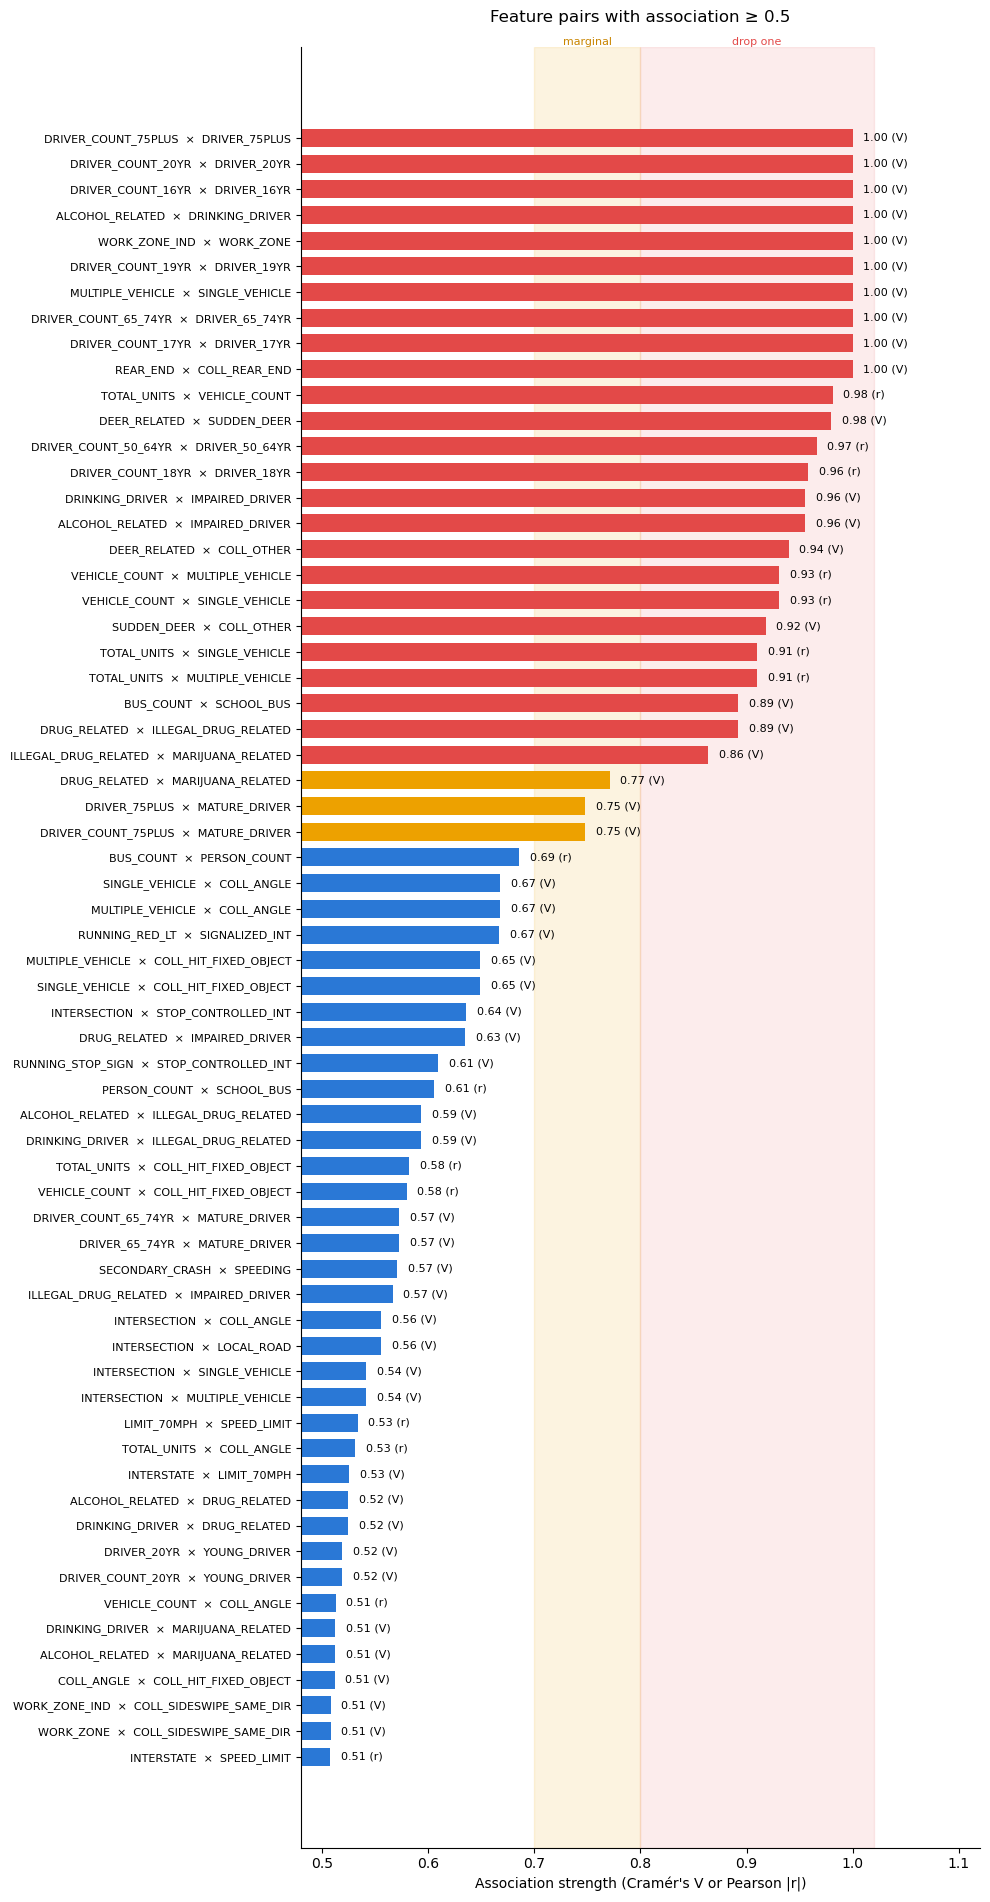

In [17]:
import matplotlib.pyplot as plt

def plot_pairs(pairs, title, min_strength=0.5):
    top = pairs[pairs["Strength"] >= min_strength].iloc[::-1]
    colors = ["#e34948" if s > 0.8 else "#eda100" if s >= 0.7 else "#2a78d6" for s in top["Strength"]]
    fig, ax = plt.subplots(figsize=(10, 0.28 * len(top) + 1.2))
    ax.axvspan(0.7, 0.8, color="#eda100", alpha=0.12)
    ax.axvspan(0.8, 1.02, color="#e34948", alpha=0.10)
    ax.barh(top["Feature A"] + "  ×  " + top["Feature B"], top["Strength"], color=colors, height=0.7)
    for i, (s, t) in enumerate(zip(top["Strength"], top["Test"])):
        ax.text(s + 0.01, i, f"{s:.2f} ({'V' if t.startswith('Cram') else 'r'})", va="center", fontsize=8)
    ax.set_xlim(min_strength - 0.02, 1.12)
    ax.set_xlabel("Association strength (Cramér's V or Pearson |r|)")
    ax.set_title(title, pad=18)
    ax.text(0.75, 1.0, "marginal", ha="center", va="bottom", fontsize=8, color="#c98500", transform=ax.get_xaxis_transform())
    ax.text(0.91, 1.0, "drop one", ha="center", va="bottom", fontsize=8, color="#e34948", transform=ax.get_xaxis_transform())
    ax.tick_params(axis="y", labelsize=8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_pairs(pairs, "Feature pairs with association ≥ 0.5")

**Pairs above 0.8: which one is dropped.** Rule: keep the broader or clearer column.

| Dropped | Kept | Reason |
|---|---|---|
| `DRIVER_COUNT_16YR` … `DRIVER_COUNT_75PLUS` (8) | `DRIVER_16YR` … `DRIVER_75PLUS` | Yes/no flag kept over its count |
| `ALCOHOL_RELATED`, `DRINKING_DRIVER` | `IMPAIRED_DRIVER` | Broader (alcohol or drugs) |
| `ILLEGAL_DRUG_RELATED` | `DRUG_RELATED` | Broader |
| `MULTIPLE_VEHICLE`, `VEHICLE_COUNT`, `TOTAL_UNITS` | `SINGLE_VEHICLE` | Opposite / counts of the same thing |
| `SUDDEN_DEER`, `COLL_OTHER` | `DEER_RELATED` | Broader; "other" is not defined |
| `SCHOOL_BUS` | `BUS_COUNT` | Broader (any bus) |
| `COLL_REAR_END` | `REAR_END` | Identical |
| `WORK_ZONE_IND` | `WORK_ZONE` | Identical |

In [18]:
to_drop = ["DRIVER_COUNT_16YR", "DRIVER_COUNT_17YR", "DRIVER_COUNT_18YR", "DRIVER_COUNT_19YR",
           "DRIVER_COUNT_20YR", "DRIVER_COUNT_50_64YR", "DRIVER_COUNT_65_74YR", "DRIVER_COUNT_75PLUS",
           "ALCOHOL_RELATED", "DRINKING_DRIVER", "ILLEGAL_DRUG_RELATED",
           "MULTIPLE_VEHICLE", "VEHICLE_COUNT", "TOTAL_UNITS", "SUDDEN_DEER", "COLL_OTHER",
           "SCHOOL_BUS", "COLL_REAR_END", "WORK_ZONE_IND"]
X = X.drop(columns=to_drop)

pairs_after = association_pairs(X.drop(columns=["MOTORCYCLE_MISSING", "STOP_CONTROLLED_INT_MISSING"]))
print(X.shape[1], "features left | strongest remaining pair:", round(pairs_after["Strength"].max(), 2))
pairs_after[pairs_after["Strength"] >= 0.7]

53 features left | strongest remaining pair: 0.77


,Feature A,Feature B,Test,Strength,p-value
0,DRUG_RELATED,MARIJUANA_RELATED,Cramér's V,0.771035,2.041095e-30
1,DRIVER_75PLUS,MATURE_DRIVER,Cramér's V,0.747780,1.042191e-28


**Nested features.** Cramér's V misses a small flag that sits entirely inside a bigger one (e.g. every marijuana crash is also an impaired-driver crash). Rule: if 100% of feature A's crashes are also in feature B **and** they are the same concept by definition, keep only the broader B. `SPEEDING` is the exception: it is inside `AGGRESSIVE_DRIVING` but has its own physical mechanism (crash energy), so it is kept.

In [19]:
from itertools import permutations

# Same-concept groups (from the data dictionary)
families = {
    "Impairment": ["IMPAIRED_DRIVER", "DRUG_RELATED", "MARIJUANA_RELATED"],
    "Older driver": ["MATURE_DRIVER", "DRIVER_65_74YR", "DRIVER_75PLUS"],
    "Young driver": ["YOUNG_DRIVER", "DRIVER_16YR", "DRIVER_17YR", "DRIVER_18YR", "DRIVER_19YR", "DRIVER_20YR"],
    "Aggressive driving": ["AGGRESSIVE_DRIVING", "RUNNING_RED_LT", "RUNNING_STOP_SIGN", "SPEEDING"],
    "Intersection type": ["INTERSECTION", "SIGNALIZED_INT", "STOP_CONTROLLED_INT"],
}

rows = []
for concept, cols in families.items():
    cols = [c for c in cols if c in X]
    for a, b in permutations(cols, 2):
        ok = X[a].isin([0, 1]) & X[b].isin([0, 1])                       # skip mean-imputed values
        inside, outside = (X[a] == 1) & ok, (X[b] == 1) & ok
        if 0 < inside.sum() < outside.sum() and (inside & outside).sum() == inside.sum():
            rows.append({"Narrow feature": a, "Its crashes": int(inside.sum()), "Inside": b,
                         "Broad crashes": int(outside.sum()), "Concept": concept})
nested = pd.DataFrame(rows, columns=["Narrow feature", "Its crashes", "Inside", "Broad crashes", "Concept"])
narrow = sorted(set(nested["Narrow feature"]) - {"SPEEDING"})           # SPEEDING kept: its own mechanism (crash energy)
X = X.drop(columns=narrow + (["STOP_CONTROLLED_INT_MISSING"] if "STOP_CONTROLLED_INT" in narrow else []))
print("Dropped nested features:", narrow)
nested

Dropped nested features: ['DRIVER_16YR', 'DRIVER_17YR', 'DRIVER_18YR', 'DRIVER_19YR', 'DRIVER_20YR', 'DRIVER_65_74YR', 'DRIVER_75PLUS', 'DRUG_RELATED', 'MARIJUANA_RELATED', 'RUNNING_RED_LT', 'RUNNING_STOP_SIGN', 'SIGNALIZED_INT', 'STOP_CONTROLLED_INT']


,Narrow feature,Its crashes,Inside,Broad crashes,Concept
0,DRUG_RELATED,5,IMPAIRED_DRIVER,12,Impairment
1,MARIJUANA_RELATED,3,IMPAIRED_DRIVER,12,Impairment
2,MARIJUANA_RELATED,3,DRUG_RELATED,5,Impairment
3,DRIVER_65_74YR,18,MATURE_DRIVER,47,Older driver
4,DRIVER_75PLUS,29,MATURE_DRIVER,47,Older driver
5,DRIVER_16YR,2,YOUNG_DRIVER,36,Young driver
6,DRIVER_17YR,7,YOUNG_DRIVER,36,Young driver
7,DRIVER_18YR,8,YOUNG_DRIVER,36,Young driver
8,DRIVER_19YR,9,YOUNG_DRIVER,36,Young driver
9,DRIVER_20YR,11,YOUNG_DRIVER,36,Young driver


**Unreliable feature.** `SECONDARY_CRASH` is yes in only 2 rural crashes (both severe, and probably the same crash listed twice), too few to trust, so it is dropped.

In [20]:
X = X.drop(columns=["SECONDARY_CRASH"])
X.shape

(221, 38)

### Step 3: SelectKBest (chi-square)

- Score every feature by its chi-square association with `FATAL_OR_SUSP_SERIOUS_INJ` and keep the top 10
- Every column is first scaled to 0–1, so numbers like `SPEED_LIMIT` don't score higher just because of their units (yes/no columns are unchanged)
- The two "was missing" flags are left out
- Chi-square says how strongly a feature is linked to the outcome, not in which direction, so the severe rate when the feature = yes is shown next to it

In [21]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

X_kbest = X.drop(columns=[c for c in ["MOTORCYCLE_MISSING", "STOP_CONTROLLED_INT_MISSING"] if c in X])
print(f"Overall severe rate: {y.mean():.1%}")
X_scaled = pd.DataFrame(MinMaxScaler().fit_transform(X_kbest), columns=X_kbest.columns)
selector = SelectKBest(chi2, k=10).fit(X_scaled, y)

ranking = pd.DataFrame({
    "Chi-square": selector.scores_,
    "p-value": selector.pvalues_,
    "Severe rate when yes": [y[X_kbest[c] == 1].mean() if X_kbest[c].between(0, 1).all() else np.nan for c in X_kbest],   # yes/no features only
}, index=X_kbest.columns).sort_values("Chi-square", ascending=False)
ranking["Selected"] = ranking.index.isin(X_kbest.columns[selector.get_support()])

top10 = ranking.index[ranking["Selected"]].tolist()
ranking.head(10).style.format({"Chi-square": "{:.2f}", "p-value": "{:.4f}", "Severe rate when yes": "{:.1%}"}, na_rep="–")

Overall severe rate: 5.9%


,Chi-square,p-value,Severe rate when yes,Selected
SPEEDING,17.29,0.0000,42.9%,True
MOTORCYCLE,15.58,0.0001,50.0%,True
ILLUMINATION_DARK,3.19,0.0742,0.0%,True
WET_ROAD,2.53,0.1116,12.5%,True
IMPAIRED_DRIVER,2.52,0.1124,16.7%,True
YOUNG_DRIVER,2.25,0.1336,0.0%,True
AGGRESSIVE_DRIVING,2.08,0.1491,8.9%,True
INTERSTATE,1.88,0.1709,0.0%,True
DEER_RELATED,1.81,0.1782,0.0%,True
COLL_HEAD_ON,1.80,0.1797,20.0%,True


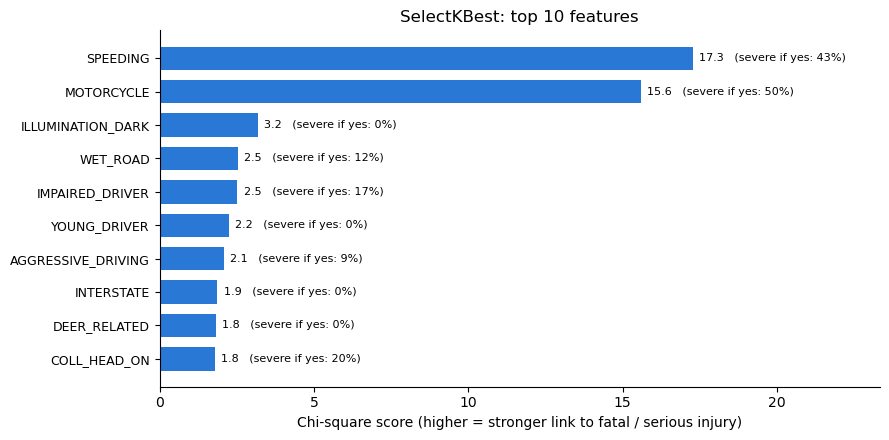

In [22]:
top = ranking.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top["Chi-square"], color="#2a78d6", height=0.7)
for i, (score, rate) in enumerate(zip(top["Chi-square"], top["Severe rate when yes"])):
    ax.text(score + 0.2, i, f"{score:.1f}   (severe if yes: {rate:.0%})" if pd.notna(rate) else f"{score:.1f}", va="center", fontsize=8)
ax.set_xlabel("Chi-square score (higher = stronger link to fatal / serious injury)")
ax.set_title("SelectKBest: top 10 features")
ax.set_xlim(0, top["Chi-square"].max() * 1.35)
ax.tick_params(axis="y", labelsize=9)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Model

- Features: the top 10 from SelectKBest
- Logistic regression with an L2 penalty (`C = 1.0`); features are standardized first
- Class imbalance handled with `class_weight="balanced"`
- 5-fold stratified cross-validation, repeated 10 times (50 test folds)

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, make_scorer, precision_score, f1_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
CLASS_LABELS = ["Not severe", "Fatal / serious injury"]
CLASS_COLORS = ["#a9a8a2", "#e34948"]

In [24]:
X_model = X[top10]
y_model = y

### Class imbalance

Few crashes are severe, so an unweighted model would predict "not severe" for everyone. Balanced class weights give each severe crash more weight, so both classes count equally in training.

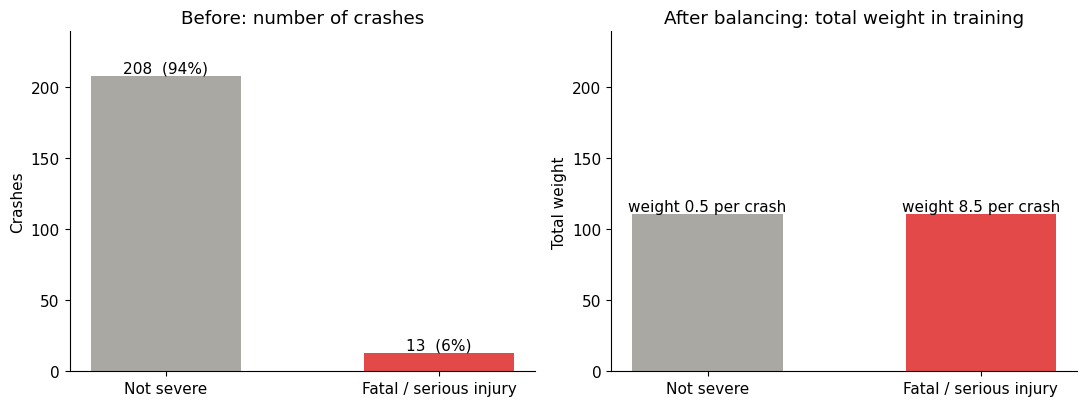

In [25]:
counts = y_model.value_counts().sort_index()
weight_per_crash = len(y_model) / (2 * counts)          # what class_weight="balanced" uses

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(CLASS_LABELS, counts, color=CLASS_COLORS, width=0.55)
for bar, n in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, n, f"{n}  ({n / len(y_model):.0%})", ha="center", va="bottom")
axes[0].set_title("Before: number of crashes")
axes[0].set_ylabel("Crashes")

bars = axes[1].bar(CLASS_LABELS, counts * weight_per_crash, color=CLASS_COLORS, width=0.55)
for bar, w in zip(bars, weight_per_crash):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"weight {w:.1f} per crash", ha="center", va="bottom")
axes[1].set_title("After balancing: total weight in training")
axes[1].set_ylabel("Total weight")
for ax in axes:
    ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()

### Cross-validated results

In [26]:
model = make_pipeline(StandardScaler(),
                      LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000))   # L2 penalty is the default
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": make_scorer(f1_score, zero_division=0), "roc_auc": "roc_auc"}
scores = cross_validate(model, X_model, y_model, cv=cv, scoring=scoring)

metric_names = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "roc_auc": "ROC AUC"}
results = pd.DataFrame({"Mean": [scores[f"test_{m}"].mean() for m in metric_names],
                        "Std": [scores[f"test_{m}"].std() for m in metric_names]},
                       index=metric_names.values()).round(3)
results

,Mean,Std
Accuracy,0.893,0.037
Precision,0.329,0.123
Recall,0.700,0.252
F1,0.432,0.139
ROC AUC,0.858,0.107


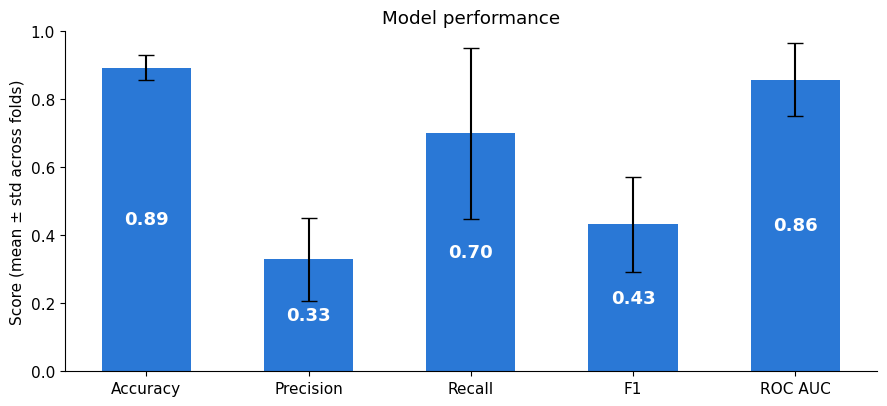

In [27]:
main = results.loc[["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]]
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(main.index, main["Mean"], yerr=main["Std"], capsize=6, color="#2a78d6", width=0.55)
for bar, v in zip(bars, main["Mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v / 2, f"{v:.2f}", ha="center", va="center",
            color="white", fontsize=13, fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("Score (mean ± std across folds)")
ax.set_title("Model performance")
plt.tight_layout()
plt.show()

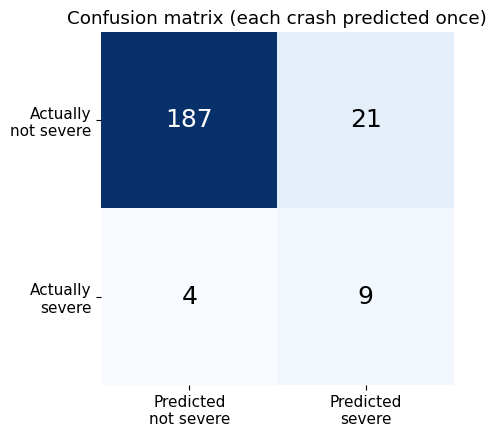

In [28]:
pred = cross_val_predict(model, X_model, y_model, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
cm = confusion_matrix(y_model, pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", fontsize=18, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted\nnot severe", "Predicted\nsevere"])
ax.set_yticks([0, 1], ["Actually\nnot severe", "Actually\nsevere"])
ax.set_title("Confusion matrix (each crash predicted once)")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

### ROC curve and AUC

How well the model ranks severe crashes above non-severe ones. 0.5 = random guessing, 1.0 = perfect.

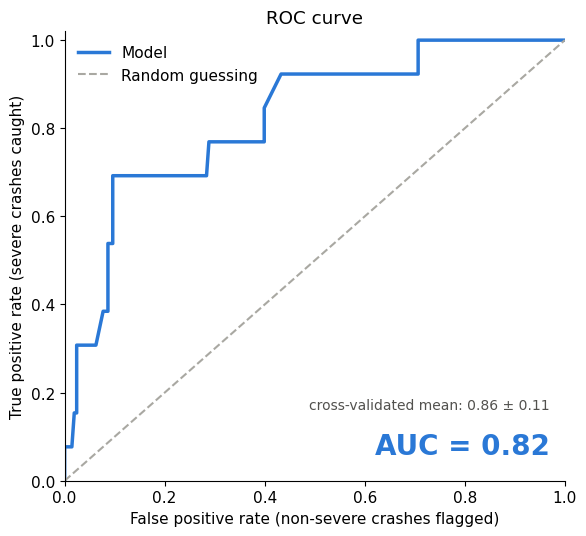

In [29]:
from sklearn.metrics import roc_curve, roc_auc_score

prob = cross_val_predict(model, X_model, y_model, method="predict_proba",
                         cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))[:, 1]
fpr, tpr, _ = roc_curve(y_model, prob)
auc = roc_auc_score(y_model, prob)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(fpr, tpr, color="#2a78d6", linewidth=2.5, label="Model")
ax.plot([0, 1], [0, 1], color="#a9a8a2", linestyle="--", linewidth=1.5, label="Random guessing")
ax.text(0.97, 0.06, f"AUC = {auc:.2f}", transform=ax.transAxes, ha="right", fontsize=20, fontweight="bold", color="#2a78d6")
ax.text(0.97, 0.16, f"cross-validated mean: {results.loc['ROC AUC', 'Mean']:.2f} ± {results.loc['ROC AUC', 'Std']:.2f}",
        transform=ax.transAxes, ha="right", fontsize=10, color="#52514e")
ax.set_xlabel("False positive rate (non-severe crashes flagged)")
ax.set_ylabel("True positive rate (severe crashes caught)")
ax.set_title("ROC curve")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

### Feature importance

Coefficients of the model fitted on all rows. Features are standardized, so the bar lengths are comparable: red raises the risk of a fatal / serious injury, blue lowers it.

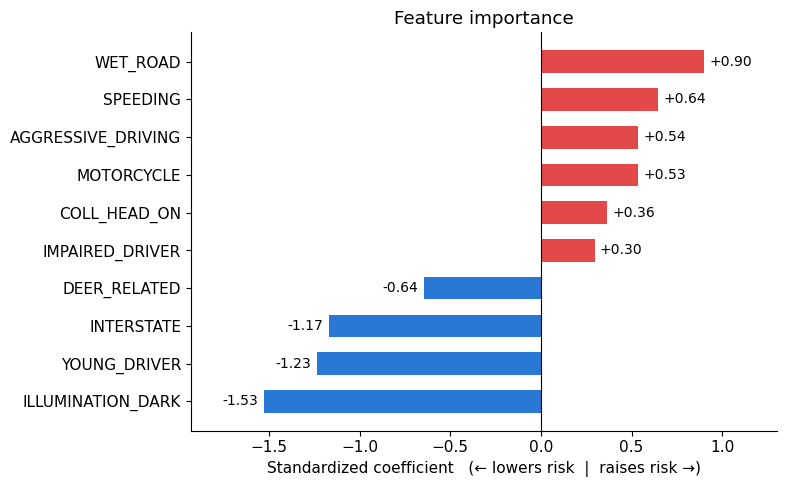

In [30]:
model.fit(X_model, y_model)
coef = pd.Series(model[-1].coef_[0], index=X_model.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coef.index, coef, color=["#e34948" if c > 0 else "#2a78d6" for c in coef], height=0.6)
for i, c in enumerate(coef):
    ax.text(c + (0.03 if c > 0 else -0.03), i, f"{c:+.2f}", va="center", ha="left" if c > 0 else "right", fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(coef.min() - 0.4, coef.max() + 0.4)
ax.set_xlabel("Standardized coefficient   (← lowers risk  |  raises risk →)")
ax.set_title("Feature importance")
plt.tight_layout()
plt.show()

### VIF check

VIF above 5 would signal multicollinearity.

In [31]:
X_const = sm.add_constant(X_model.astype(float))
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])]},
                   index=X_model.columns).round(2).sort_values("VIF", ascending=False)
vif

,VIF
AGGRESSIVE_DRIVING,1.44
DEER_RELATED,1.43
INTERSTATE,1.18
IMPAIRED_DRIVER,1.15
ILLUMINATION_DARK,1.09
YOUNG_DRIVER,1.07
WET_ROAD,1.06
SPEEDING,1.05
MOTORCYCLE,1.05
COLL_HEAD_ON,1.05


## Results (rural roads)

221 rural crashes, 13 fatal / serious.

**Features (10):** SPEEDING, MOTORCYCLE, ILLUMINATION_DARK, WET_ROAD, IMPAIRED_DRIVER, YOUNG_DRIVER, AGGRESSIVE_DRIVING, INTERSTATE, DEER_RELATED, COLL_HEAD_ON

| Accuracy | Precision | Recall | F1 |
|---|---|---|---|
| 0.89 | 0.33 | 0.70 | 0.43 |

- The model catches 70% of fatal / serious rural crashes; about 1 in 3 of its "severe" flags is correct
- Raise the risk: wet road, speeding, aggressive driving, motorcycle, head-on, impaired driver
- Lower the risk: dark-condition, young-driver, interstate and deer crashes (none of these were severe)
- Only 13 severe crashes, so results vary between folds (recall ± 0.25)
- All VIFs < 1.5: no multicollinearity